In [ ]:
#from memoria_icm.datos import cargar_df
#import memoria_icm.graficos as graficos

import os
import matplotlib.pyplot as plt, pandas as pd, numpy as np, seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import acf
from memoria_icm.graficos import guardar_figura, crear_subplots
from memoria_icm.datos import datos_trackeo, datos_calculados, cargar_df

In [ ]:
print(datos_trackeo)
print(datos_calculados)

variables = datos_calculados.union({'v','a'})
print(variables)

df = cargar_df()

df.head()

{'y', 'v', 'x', 'vx', 'vy', 'a', 'ay', 'ax', 't'}
{'a_angular', 'duracion_video', 'theta_rad', 'r', 'v_angular', 'theta_deg'}
{'a', 'a_angular', 'duracion_video', 'theta_rad', 'v', 'r', 'v_angular', 'theta_deg'}


Conexión cerrada.
Dimensión de los datos: (86200, 20)
Estas columnas no están en el DataFrame: ['curv_mediana', 'curv_promedio', 'despl_relativo', 'v_promedio', 'desplazamiento']
Preprocesamiento completado. Shape final: (85911, 27)


,id,t,x,y,vx,vy,v,ax,ay,a,...,video_analizado,larva_unica,duracion_video,x_centrada,y_centrada,r,theta_rad,theta_deg,v_angular,a_angular
1,0,0.073174,1.981245,-0.629966,-0.030119,-0.122312,0.125966,NaN,NaN,NaN,...,1,1,11.88146,0.000000,0.000000,0.000000,-2.284448,229.110751,-22.881871,-22.881871
2,0,0.123811,1.972938,-0.639559,-0.059602,-0.092332,0.109898,-0.117845,0.754723,0.763868,...,1,1,11.88146,-0.008307,-0.009593,0.012690,-2.144033,237.155930,0.548799,0.548799
3,0,0.181472,1.974790,-0.639965,0.000456,-0.021718,0.021723,1.482924,0.656206,1.621626,...,1,1,11.88146,-0.006455,-0.009999,0.011902,-2.181986,234.981439,5.536481,5.536481
4,0,0.224938,1.972984,-0.641756,0.041020,-0.068821,0.080119,0.133586,-0.786954,0.798211,...,1,1,11.88146,-0.008261,-0.011790,0.014396,-1.769996,258.586712,7.212013,7.212013
5,0,0.262257,1.978104,-0.645525,0.046345,-0.100977,0.111105,-0.289838,-0.871793,0.918710,...,1,1,11.88146,-0.003141,-0.015559,0.015873,-1.730447,260.852684,0.186403,0.186403


Figura guardada en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\CC_E\id_0_a.png
Figura guardada en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\CC_E\id_0_a_angular.png
Figura guardada en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\CC_E\id_0_duracion_video.png
Figura guardada en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\CC_E\id_0_theta_rad.png
Figura guardada en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\CC_E\id_0_v.png
Figura guardada en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\CC_E\id_0_r.png
Figura guardada en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\CC_E\id_0_v_angular.png
Figura guardada en

c:\Users\franc\anaconda3\envs\tesis\Lib\site-packages\statsmodels\tsa\stattools.py:702: RuntimeWarning: invalid value encountered in divide
  acf = avf[: nlags + 1] / avf[0]


Figura guardada en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\CC_E\id_18_duracion_video.png
Figura guardada en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\CC_E\id_18_theta_rad.png
Figura guardada en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\CC_E\id_18_v.png
Figura guardada en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\CC_E\id_18_r.png
Figura guardada en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\CC_E\id_18_v_angular.png
Figura guardada en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\CC_E\id_18_theta_deg.png
Figura guardada en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\CC_E\id_19_a.png
Figura guar

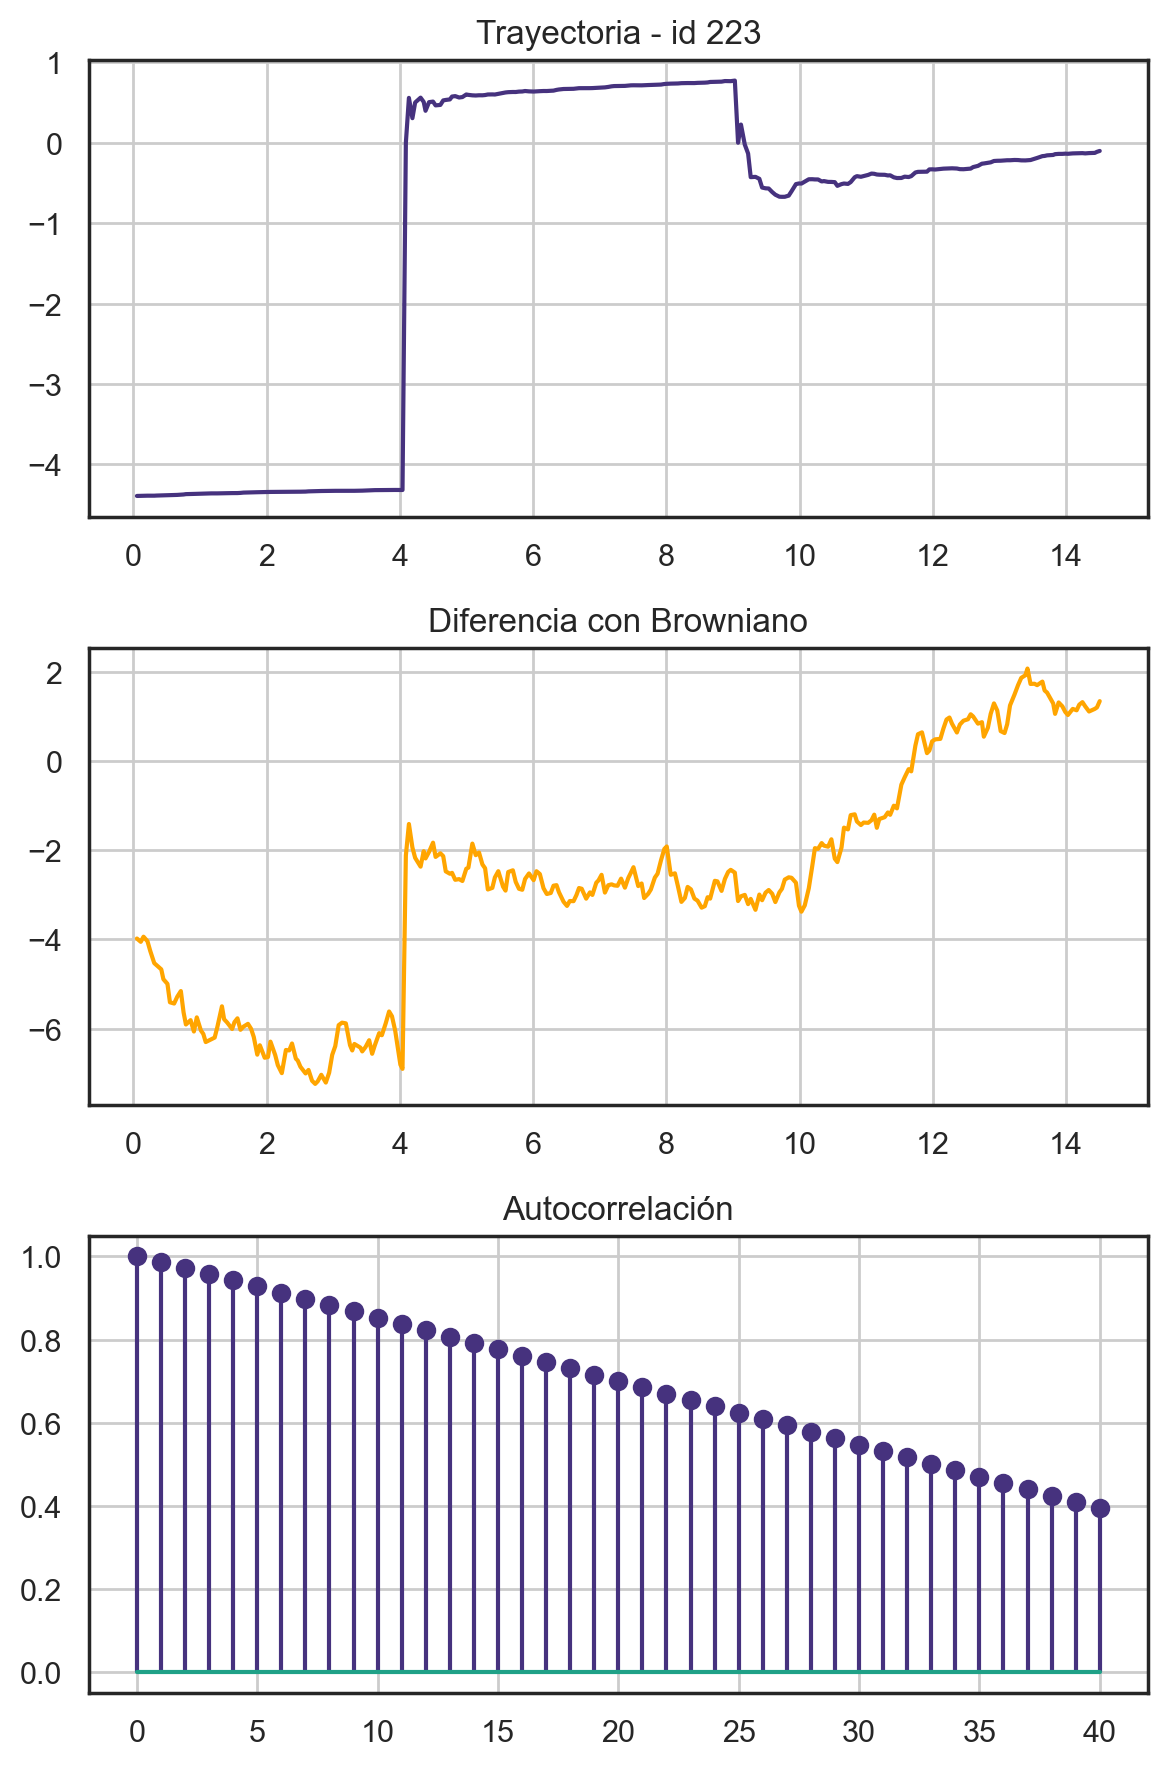

In [ ]:
# grupos = {
#     'CC_E': df[(df['especie'] == 'CC') & (df['tratamiento'] == 'E')],
#     'CC_R': df[(df['especie'] == 'CC') & (df['tratamiento'] == 'R')],
#     'LA_E': df[(df['especie'] == 'LA') & (df['tratamiento'] == 'E')],
#     'LA_R': df[(df['especie'] == 'LA') & (df['tratamiento'] == 'R')]
# }

# for nombre_grupo, df_grupo in grupos.items():
#     for id_larva, df_larva in df_grupo.groupby('id'):
#         for variable in variables:
#             t_vals = df_larva['t'].values
#             variable_vals = df_larva[variable].values

#             # Simular Browniano estándar en mismo grid
#             dt_vals = np.diff(t_vals, prepend=t_vals[0] - (t_vals[1] - t_vals[0]))
#             dW = np.random.normal(0, np.sqrt(dt_vals))
#             W = np.cumsum(dW)

#             diff = variable_vals - W
#             acf_vals = acf(variable_vals, nlags=min(40, len(variable_vals)//2), fft=True)

#             fig, axs = crear_subplots(3, orientacion='vertical', figsize_base=(6, 3))

#             axs[0].plot(t_vals, variable_vals, label= f'Trayectoria {variable}')
#             axs[0].set_title(f'Trayectoria - id {id_larva}')
#             axs[0].grid(True)

#             axs[1].plot(t_vals, diff, label=f'{variable} - W(t)', color='orange')
#             axs[1].set_title('Diferencia con Browniano')
#             axs[1].grid(True)

#             axs[2].stem(range(len(acf_vals)), acf_vals)
#             axs[2].set_title('Autocorrelación')
#             axs[2].grid(True)

#             plt.tight_layout()
#             guardar_figura(nombre=f'id_{id_larva}_{variable}', subcarpeta=nombre_grupo)
#             plt.close(fig)

In [ ]:
#df = cargar_df()


#este dataframe viene SIN las filas de tiempo 0.0 en cada video; a las 86200 se le quitan exactamente 289 filas
#(filas iniciales de cada video que generan datos vacíos o no interpretables en v, a, y variables angulares)

Conexión cerrada.
Dimensión de los datos: (86200, 20)
Estas columnas no están en el DataFrame: ['curv_mediana', 'despl_relativo', 'desplazamiento', 'curv_promedio', 'v_promedio']
Preprocesamiento completado. Shape final: (85911, 27)


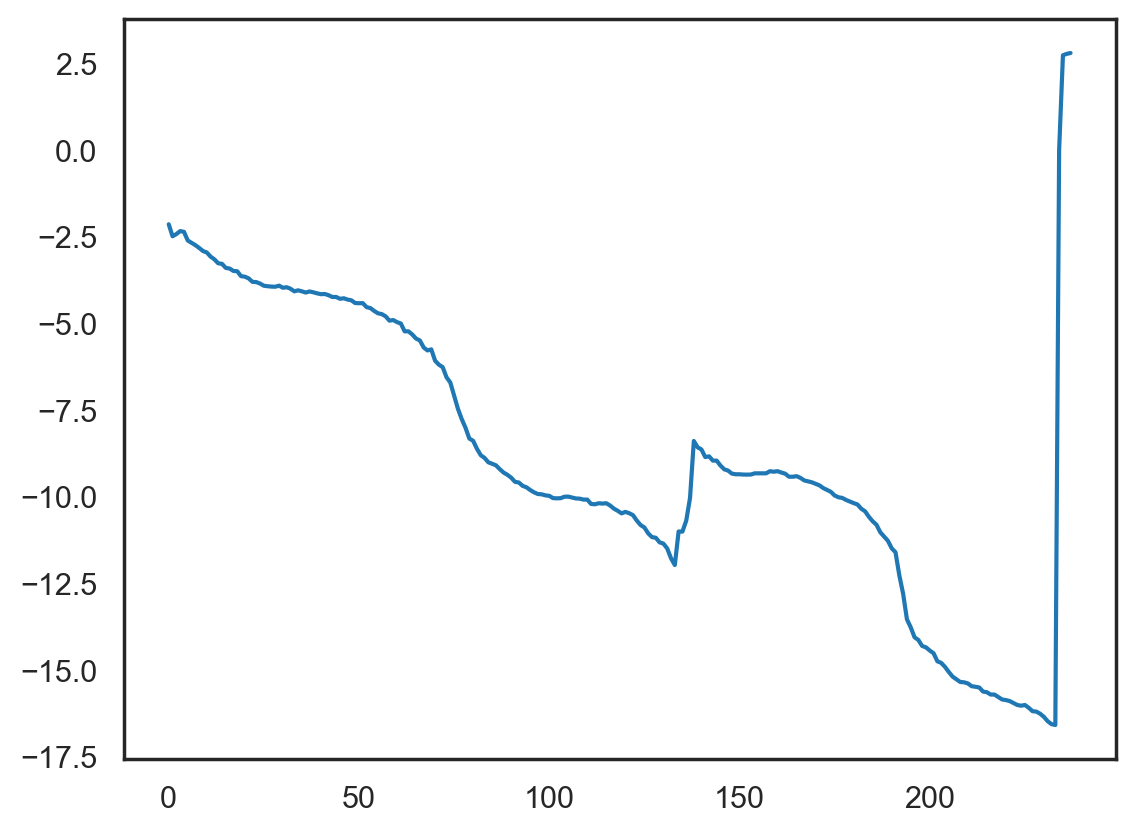

In [11]:
individuo = df[df['id'] == 4]
diffs = []
diff_serie = individuo['theta_rad']
#diff_serie = diff_serie.diff()
diffs.append(diff_serie)
diffs = pd.concat(diffs, ignore_index=True)
#graficos.plot(y= diff_serie, title = "", kind = 'plot')
plt.plot(diffs, label='Diferencias de r')

#en qué momento, en promedio, dejan de de-correlacionarse las diferencias?
#definir el umbral de autocorrelación como 0.05 aprox

In [ ]:
#from memoria_icm.datos import datos_calculados

variables = {'v','a', 'theta_rad'} #modificar conjunto

UMBRAL = 0.05  

acf_dict  = {var: {} for var in variables}
pacf_dict = {var: {} for var in variables}
dt_dict = {}
threshold_lag_dict  = {var: {} for var in variables}
threshold_time_dict = {var: {} for var in variables}

videos = sorted(df['id'].unique())

for vid in videos:
    sub = df[df['id'] == vid].sort_values(by='t')
    tiempos = sub['t'].values
    if tiempos.size >= 2:
        dt_dict[vid] = np.mean(np.diff(tiempos))

    for var in variables:

        serie = sub[var].values
        diff_serie = np.diff(serie)

        if diff_serie.size >= 1:
            acf_vals = acf(diff_serie, nlags=diff_serie.size - 1)
        else:
            acf_vals = np.array([1.0])

        acf_dict[var][vid] = acf_vals

        M = diff_serie.size
        if M >= 2:
            nlags_pacf = (M // 2) - 1
            if nlags_pacf >= 1:
                pacf_vals = pacf(diff_serie, nlags=nlags_pacf, method='ld')

        pacf_dict[var][vid] = pacf_vals

for var in variables:
    for vid in videos:
        acf_vals = acf_dict[var][vid]
        idx = np.where(np.abs(acf_vals) <= UMBRAL)[0]
        if idx.size > 0:
            lag0 = int(idx[0])
        else:
            lag0 = len(acf_vals) - 1

        threshold_lag_dict[var][vid] = lag0

        #conversión a [s]
        dt_vid = dt_dict[vid]
        if np.isnan(dt_vid):
            threshold_time_dict[var][vid] = np.nan
        else:
            threshold_time_dict[var][vid] = lag0 * dt_vid

for var in variables:
    lags_arr = np.array(list(threshold_lag_dict[var].values()), dtype=float)
    times_arr = np.array(list(threshold_time_dict[var].values()), dtype=float)

    lag_prom = np.nanmean(lags_arr)
    lag_std  = np.nanstd(lags_arr)
    tiempo_prom = np.nanmean(times_arr)
    tiempo_std  = np.nanstd(times_arr)

    print(f"Variable: {var}")
    print(f"Lag promedio (|ACF|≤{UMBRAL}): {lag_prom:.1f} ± {lag_std:.1f} lags")
    print(f"Tiempo promedio: {tiempo_prom:.3f} ± {tiempo_std:.3f} s")
    print("----------")


Variable: v
Lag promedio (|ACF|≤0.05): 294.8 ± 76.8 lags
Tiempo promedio: 14.729 ± 3.835 s
Variable: theta_deg
Lag promedio (|ACF|≤0.05): 4.1 ± 18.2 lags
Tiempo promedio: 0.207 ± 0.919 s
Variable: a_angular
Lag promedio (|ACF|≤0.05): 4.6 ± 18.0 lags
Tiempo promedio: 0.228 ± 0.909 s
Variable: theta_rad
Lag promedio (|ACF|≤0.05): 5.1 ± 18.8 lags
Tiempo promedio: 0.256 ± 0.948 s
Variable: r
Lag promedio (|ACF|≤0.05): 27.8 ± 25.3 lags
Tiempo promedio: 1.392 ± 1.266 s
Variable: a
Lag promedio (|ACF|≤0.05): 295.3 ± 75.3 lags
Tiempo promedio: 14.754 ± 3.764 s
Variable: v_angular
Lag promedio (|ACF|≤0.05): 5.4 ± 18.1 lags
Tiempo promedio: 0.268 ± 0.910 s


In [ ]:
#from memoria_icm.graficos import (aplicar_configuracion_global, crear_subplots, guardar_figura, plot)

#aplicar_configuracion_global()

variables = {'v', 'a', 'a_angular'}
umbral = 0.05
MAX_LAGS = 50

BASE_FIGURAS = os.path.join("..", "..", "resultados", "unfinished", "autocorrelación por variable")

def procesar_un_video(df: pd.DataFrame, vid, var, umbral, max_lags):
    sub = df[df['id'] == vid].sort_values(by='t')
    tiempos = sub['t'].values
    serie = sub[var].values #esto es un array de np
    diff_serie = np.diff(serie)

    N = len(serie)
    M = len(diff_serie)
    nlags_orig = min(N - 1, max_lags) if N >= 2 else 0
    nlags_diff = min(M - 1, max_lags) if M >= 2 else 0

    pacf_lags_orig = min(nlags_orig, max(0, (N // 2) - 1))
    pacf_lags_diff = min(nlags_diff, max(0, (M // 2) - 1))

    #acf_orig = acf(serie, nlags=nlags_orig) ACF SERIE NORMAL

    #pacf_orig = pacf(serie, nlags=pacf_lags_orig) PACF SERIE NORMAL

    #acf_diff = acf(diff_serie, nlags=nlags_diff) ACF SERIE DIF

    #pacf_diff = pacf(diff_serie, nlags=pacf_lags_diff) PACF SERIE DIF

    fig, axs = crear_subplots(6, orientacion='grid', figsize_base=(4, 3))

    #(1,1) Serie original vs. tiempo
    plot(
        x=tiempos,
        y=serie,
        kind='line',
        ax=axs[0],
        title=f"{var} – Video {vid}",
        xlabel="t [s]",
        ylabel=var
    )

    #(1,2) ACF original
    if nlags_orig > 0:
        plot_acf(
            serie,
            ax=axs[1],
            lags=nlags_orig,
            alpha=None,
            zero=False
        )
        axs[1].set_title("ACF original")
        axs[1].set_xlabel("Lag")
        axs[1].set_ylabel("ACF")
        axs[1].axhline(umbral, color='red', ls='--', lw=0.7)
        axs[1].axhline(-umbral, color='red', ls='--', lw=0.7)

    #(1,3) PACF original
    if pacf_lags_orig > 0:
        plot_pacf(
            serie,
            ax=axs[2],
            lags=pacf_lags_orig,
            alpha=None,
            method='ld',
            zero=False
        )
        axs[2].set_title("PACF original")
        axs[2].set_xlabel("Lag")
        axs[2].set_ylabel("PACF")

    #(2,1) Serie diferenciada vs. tiempo
    tiempos_diff = tiempos[1:]
    plot(
        x=tiempos_diff,
        y=diff_serie,
        kind='line',
        ax=axs[3],
        title="Serie diferenciada",
        xlabel="t [s]",
        ylabel=f"Δ{var}"
    )

    #(2,2) ACF diferenciada (barras)
    if nlags_diff > 0:
        plot_acf(
            diff_serie,
            ax=axs[4],
            lags=nlags_diff,
            alpha=None,
            zero=False
        )
        axs[4].set_title("ACF diferenciada")
        axs[4].set_xlabel("Lag")
        axs[4].set_ylabel("ACF")
        axs[4].axhline(umbral, color='red', ls='--', lw=0.7)
        axs[4].axhline(-umbral, color='red', ls='--', lw=0.7)

    #(2,3) PACF diferenciada (barras)
    if pacf_lags_diff > 0:
        plot_pacf(
            diff_serie,
            ax=axs[5],
            lags=pacf_lags_diff,
            alpha=None,
            method='ld',
            zero=False
        )
        axs[5].set_title("PACF diferenciada")
        axs[5].set_xlabel("Lag")
        axs[5].set_ylabel("PACF")
    fig.suptitle(f"Video {vid} – Variable: {var}", fontsize=12, y=1.02)
    fig.tight_layout()

    #guardado
    nombre_archivo = f"video_{vid}"
    guardar_figura(nombre_archivo, subcarpeta=var, formato='png', dpi=300)
    plt.close(fig)

if True: #acá iba otra condición que quité por simplicidad en vez de identar todo el código
    indices = sorted(df['id'].unique())

    for var in variables:
        carpeta_var = os.path.join(BASE_FIGURAS, var)
        os.makedirs(carpeta_var, exist_ok=True)

        print(f"Procesando variable: {var}")
        for vid in indices:
            procesar_un_video(df, vid, var, umbral, MAX_LAGS)

    print("Terminado. Cada variable tiene su carpeta en 'figuras/<variable>'.")


Procesando variable: v
Figura guardada en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\v\video_0.png
Figura guardada en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\v\video_1.png
Figura guardada en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\v\video_3.png
Figura guardada en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\v\video_4.png
Figura guardada en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\v\video_5.png
Figura guardada en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\v\video_6.png
Figura guardada en: C:\Users\franc\OneDrive\Documentos\Memoria de título\Códigos\Memoria-ICM\Código\resultados\figuras\v\video_7.png
Figura guardada en: C:\Users\franc\OneDrive\Do

_____________________________________

In [12]:
# import pandas as pd
# import matplotlib.pyplot as plt
# from statsmodels.graphics.tsaplots import plot_acf
# from memoria_icm.datos import datos_trackeo

# variables_acf = list(datos_trackeo - {'t','x','y','vx', 'vy', 'ax', 'ay'})

# for grupo in df['id']:
#     for variable in variables_acf:
#         diffs = []
#         diff_serie = grupo[variable].diff().dropna()
#         diffs.append(diff_serie)

#     diffs_total = pd.concat(diffs, ignore_index=True)    
    
#     plt.figure(figsize=(12, 6))
#     max_lags = min(100, len(diffs_total) // 2 -1)
#     plot_acf(diffs_total, lags=max_lags, title=f'Autocorrelograma - {variable}.diff()', alpha=0.05)
#     plt.xlabel(f'Lag')
#     plt.ylabel('ACF')
#     plt.grid(True)
#     plt.show()

# #acfs hechos concatenando TODOS los diffs de cada id, para ver si hay algún patrón común en todos los ids
# #quizá ordenar los valores antes de?
# #para ver patrones comunes, tendría que hacer un gráfico por id? check this